# Features, Models and the Frozen Model
Notebook 01 (EDA) ended with a table of findings and the actions they lead to: hidden missing values, columns that drift with time, about 1% fraud, a strong link between age and fraud, and differences between the variants. This notebook carries out those actions and builds the project's model:

- **Section 2** fixes the protocol and the terms used by every notebook.
- **Sections 3-4** turn notebook 01's findings into preprocessing and features, testing each feature idea on the validation month.
- **Sections 5-6** compare logistic regression, LightGBM and XGBoost, then tune all three with the same effort.
- **Section 7** freezes the best one (XGBoost, 5 seeds) with a threshold picked on month 5.
- **Section 8** tests it once on months 6-7 of Base and all 5 variants.

The frozen model, its settings and thresholds are the starting point of every later notebook.

## **1. Imports**

In [9]:
import os
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

# Plot settings
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREY = '#8a8a8a'
MODEL_COLOURS = {'logistic_regression': '#2a78d6', 'lightgbm': '#eb6834', 'xgboost': '#1baf7a'}
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

## **2. Load and Split**
The evaluation rules are fixed here, before any model is trained, and are the same for every model and every dataset:

| Months | Used for |
|---|---|
| 0-3 | training the models |
| 4 | comparing models and tuning (validation) |
| 5 | picking the threshold for the final model |
| 6-7 | final results, on Base and on all 5 variants (section 8 only) |

- Models are trained and tuned on **Base only**. The final model is then scored, unchanged, on the test months of every variant.
- Every model is trained with 5 seeds, and results are reported as mean ± standard deviation.
- **Main metric: recall at 5% false positive rate (FPR)** - if at most 5% of genuine applications may be flagged, what share of fraud is caught?
- **Threshold.** The final model's threshold is the one that flags 5% of genuine applications on month 5; it is then applied unchanged to every test set.
- **Fairness.** Age groups are 50+ vs under 50. The main fairness measure is **predictive equality** (defined below).
- **`month` is never a model feature.**
- **Once the test results (section 8) have been run, the earlier sections are not changed**, so the test results never steer the model.

This is the protocol of the whole project: notebooks 03-06 follow the same rules.

In [10]:
DATA_DIR = '../data'
DATASET_FILES = {
    'base': 'Base.csv',
    'variant_i': 'Variant I.csv',
    'variant_ii': 'Variant II.csv',
    'variant_iii': 'Variant III.csv',
    'variant_iv': 'Variant IV.csv',
    'variant_v': 'Variant V.csv',
}
TARGET = 'fraud_bool'

TRAIN_MONTHS = [0, 1, 2, 3]
VALIDATION_MONTHS = [4]
CALIBRATION_MONTHS = [5]
TEST_MONTHS = [6, 7]

SEEDS = [0, 1, 2, 3, 4]
TARGET_FPR = 0.05   # at most 5% of genuine applications may be flagged

In [11]:
base = pd.read_csv(f'{DATA_DIR}/{DATASET_FILES["base"]}')

train = base[base['month'].isin(TRAIN_MONTHS)]
validation = base[base['month'].isin(VALIDATION_MONTHS)]
calibration = base[base['month'].isin(CALIBRATION_MONTHS)]
# The test months (6-7) are only loaded in section 8, after the final model is frozen

y_train = train[TARGET]
y_validation = validation[TARGET]
y_calibration = calibration[TARGET]

for name, part in [('train', train), ('validation', validation), ('calibration', calibration)]:
    print(f'{name:12s} {len(part):,} rows, {part[TARGET].sum():,} fraud cases')

train        547,975 rows, 5,288 fraud cases
validation   127,691 rows, 1,452 fraud cases
calibration  119,323 rows, 1,411 fraud cases


In [12]:
def recall_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """Share of fraud caught when at most target_fpr of genuine applications are flagged."""
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1   # last point still within the budget
    return tpr[i]


def threshold_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """The score threshold behind recall_at_fpr: applications with score >= threshold are flagged."""
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1
    return thresholds[i]

### **2.1 Terms Used in Every Notebook**
Two different numbers are both called "recall" in the project. These definitions are the ones every notebook uses:

| Term | Meaning |
|---|---|
| **recall** | share of fraud cases the system flags, **at its operating point** (the flags it really makes). In section 8's table: "recall at threshold" |
| **recall at 5% FPR** | ranking quality of a model alone: the recall it would have if the threshold were re-picked on the evaluated data's own labels to flag exactly 5% of genuine applications (this notebook's tuning metric). It needs the labels, so a deployed system cannot achieve it; it describes the model, not the system |
| **FPR** | share of genuine applications the system flags (false alarms / genuine applications) |
| **precision** | share of flagged applications that are fraud |
| **alert rate** | share of all applications flagged |
| **predictive equality (PE)** | lower group FPR / higher group FPR, for 50+ against under 50 (1 = equal; 0.8 = the four-fifths reference) |
| **equal opportunity (EO)** | lower group recall / higher group recall |
| **cost per 10,000** | (R x missed fraud + false alarms) per 10,000 applications, R = cost of a missed fraud relative to a false alarm |

## **3. Preprocessing**
These steps come from the EDA summary.

| Step | Why (EDA) |
|---|---|
| `-1` becomes NaN in `prev_address_months_count`, `current_address_months_count`, `bank_months_count`, `session_length_in_minutes` and `device_distinct_emails_8w`, plus a `<column>_missing` flag | Missing values are hidden as `-1`, and being missing is linked to fraud |
| Negative values become NaN in `intended_balcon_amount`, plus an `intended_balcon_amount_missing` flag | The datasheet says any negative amount is a missing value (74% of rows) |
| Drop `device_fraud_count` | Always 0 |
| Round `income` to 1 decimal place | Floating-point noise |
| Fix the list of categories | The same categories appear in all six files, so a model never meets an unknown one |
| Drop `x1` / `x2` | Only in Variants III and V; the Base model never sees them |

In [13]:
MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
CATEGORICAL_COLUMNS = list(CATEGORY_LEVELS)


def preprocess(df, missing_flags=True):
    """The cleaning steps above. Returns a new table; df itself is not changed."""
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')

In [18]:
cleaned = preprocess(train)
# Missing values left for the models to handle
missing_counts = cleaned.isna().sum()
missing_counts[missing_counts > 0].to_frame('missing values')

,missing values
prev_address_months_count,377557
current_address_months_count,2309
intended_balcon_amount,393220
bank_months_count,136894
session_length_in_minutes,995
device_distinct_emails_8w,226


LightGBM and XGBoost handle NaN, skewed columns and categories by themselves. Logistic regression doesn't, so its model (section 4.1) also fills missing values with the median, log-transforms the long-tailed columns, one-hot encodes the categories (merging the tiny ones: AE, CG, BF, BG) and scales every column. These steps are learned from the training months only.

## **4. Feature Engineering**

### **4.1 Models and Scoring**
Every experiment from here on is scored the same way: fit the model on months 0-3 once per seed, then measure recall at 5% FPR on month 4.

The tree models start from each library's default settings, except that each tree only sees a random 80% of rows and columns. Without that randomness all seeds would give the exact same model.

In [19]:
MODEL_NAMES = ['logistic_regression', 'lightgbm', 'xgboost']

# Long right tails (EDA 3.3): log-transformed for logistic regression only
LOG_COLUMNS = ['days_since_request', 'prev_address_months_count', 'session_length_in_minutes',
               'bank_branch_count_8w', 'intended_balcon_amount', 'current_address_months_count']


def make_model(name, seed, params=None):
    """One of the three candidate models. `params` overrides the starting settings."""
    params = params or {}

    if name == 'lightgbm':
        settings = {'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, **params}
        return LGBMClassifier(**settings, random_state=seed, verbose=-1)

    if name == 'xgboost':
        settings = {'subsample': 0.8, 'colsample_bytree': 0.8, **params}
        return XGBClassifier(**settings, random_state=seed, tree_method='hist', enable_categorical=True)

    if name == 'logistic_regression':
        settings = {'C': 1.0, **params}
        log_columns = Pipeline([
            ('fill', SimpleImputer(strategy='median')),
            ('log', FunctionTransformer(np.log1p)),
            ('scale', StandardScaler()),
        ])
        # categories under 0.5% of rows are merged into one "infrequent" column
        categories = OneHotEncoder(min_frequency=0.005, handle_unknown='infrequent_if_exist',
                                   sparse_output=False)
        other_columns = Pipeline([
            ('fill', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ])
        prepare = ColumnTransformer([
            ('log', log_columns, LOG_COLUMNS),
            ('categories', categories, CATEGORICAL_COLUMNS),
        ], remainder=other_columns)
        return Pipeline([
            ('prepare', prepare),
            ('model', LogisticRegression(**settings, max_iter=1000, random_state=seed)),
        ])

    raise ValueError(f'unknown model: {name}')


def validation_results(model_name, X_train, X_validation, params=None):
    """Fit the model once per seed on months 0-3 and score it on month 4.
    Returns one row of metrics per seed, and the month-4 scores of the first seed (for plots)."""
    rows = []
    first_seed_scores = None
    for seed in SEEDS:
        model = make_model(model_name, seed, params)
        model.fit(X_train, y_train)
        scores = model.predict_proba(X_validation)[:, 1]
        if first_seed_scores is None:
            first_seed_scores = scores
        rows.append({
            'seed': seed,
            'recall_at_5pct_fpr': recall_at_fpr(y_validation, scores),
            'roc_auc': roc_auc_score(y_validation, scores),
            'pr_auc': average_precision_score(y_validation, scores),
        })
    return pd.DataFrame(rows), first_seed_scores


def summarise(results):
    """Average over the seeds (and the spread of the main metric)."""
    return {
        'recall@5%FPR (mean)': results['recall_at_5pct_fpr'].mean(),
        'recall@5%FPR (std)': results['recall_at_5pct_fpr'].std(),
        'ROC-AUC (mean)': results['roc_auc'].mean(),
        'PR-AUC (mean)': results['pr_auc'].mean(),
    }

### **4.2 Feature Options**
The ideas tested, each from the EDA:

| Experiment | Why (EDA) |
|---|---|
| + missing flags | Being missing is linked to fraud (e.g. 1.28% vs 0.27% for `prev_address_months_count`) |
| Drifting columns: drop / ratio / month rank | `velocity_*` and `zip_count_4w` fall steadily over time (EDA 3.7) |
| + `valid_phones` | Number of valid phone numbers given (0, 1 or 2) |
| Without `customer_age` | Shows how much accuracy age adds |

The drifting-column options:
- **drop**: remove `velocity_6h`, `velocity_24h`, `velocity_4w`, `zip_count_4w`
- **ratio**: replace them with `velocity_6h / velocity_24h`, `velocity_24h / velocity_4w` and `zip_count_4w / velocity_4w`. A fall in overall volume affects both parts of a ratio, so it mostly cancels out
- **month rank**: replace each value with its percentile within its own month

In [20]:
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    """Preprocessing plus feature engineering, with each experiment as an option.
    The final model uses make_features(df, **FINAL_FEATURES)."""
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            # month is only used to group the rows here, it is not a feature
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    # the answer, and a column that only tracks time, are never features
    return X.drop(columns=[TARGET, 'month'])

### **4.3 Drift Check for the Drifting Columns**
Month 4 is right next to the training months, so its accuracy can't show the drift problem: the test months are further away. So first we measure how much each version of the drifting columns moves between months 0-3 and month 5, using the Population Stability Index from EDA 3.7 (below 0.1 = stable, above 0.25 = large shift).

In [28]:
def psi(reference, current, bins=10):
    """Population Stability Index between two samples of the same column (as in EDA 3.7)."""
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0] = -np.inf
    edges[-1] = np.inf
    ref_pct = pd.cut(reference, edges).value_counts(normalize=True)
    cur_pct = pd.cut(current, edges).value_counts(normalize=True).reindex(ref_pct.index, fill_value=0)
    ref_pct = ref_pct.clip(lower=0.0001)
    cur_pct = cur_pct.clip(lower=0.0001)
    return ((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)).sum()


versions = {
    'keep': DRIFTING_COLUMNS,
    'ratio': ['velocity_6h_vs_24h', 'velocity_24h_vs_4w', 'zip_count_vs_velocity_4w'],
    'rank': [f'{col}_month_rank' for col in DRIFTING_COLUMNS],
}

rows = []
for option, columns in versions.items():
    X_ref = make_features(train, drifting=option)
    X_cur = make_features(calibration, drifting=option)
    for col in columns:
        rows.append({'option': option, 'column': col, 'PSI (months 0-3 vs month 5)': psi(X_ref[col], X_cur[col])})

pd.DataFrame(rows).round(3)

,option,column,PSI (months 0-3 vs month 5)
0,keep,velocity_6h,0.500
1,keep,velocity_24h,0.976
2,keep,velocity_4w,4.480
3,keep,zip_count_4w,0.234
4,ratio,velocity_6h_vs_24h,0.043
5,ratio,velocity_24h_vs_4w,0.080
6,ratio,zip_count_vs_velocity_4w,0.056
7,rank,velocity_6h_month_rank,0.000
8,rank,velocity_24h_month_rank,0.000
9,rank,velocity_4w_month_rank,0.000


### **4.4 Experiments**
Each experiment changes **one** thing compared with a plain starting point (no missing flags, drifting columns kept as they are, no hand-made features, age included). The last row is the final choice. Two kinds of model are checked, because they react differently to features: LightGBM (trees) and logistic regression (linear).

In [29]:
# The final choice, made after the drift check above and the experiments below
FINAL_FEATURES = dict(missing_flags=True, drifting='ratio', valid_phones=False, include_age=True)

experiments = {
    'starting point': dict(),
    '+ missing flags': dict(missing_flags=True),
    'drifting columns: drop': dict(drifting='drop'),
    'drifting columns: ratio': dict(drifting='ratio'),
    'drifting columns: month rank': dict(drifting='rank'),
    '+ valid_phones': dict(valid_phones=True),
    'without customer_age': dict(include_age=False),
    'final choice': FINAL_FEATURES,
}

rows = []
for experiment, options in experiments.items():
    X_tr = make_features(train, **options)
    X_va = make_features(validation, **options)
    lightgbm_results, _ = validation_results('lightgbm', X_tr, X_va)
    logistic_results, _ = validation_results('logistic_regression', X_tr, X_va)
    rows.append({
        'experiment': experiment,
        'features': X_tr.shape[1],
        'LightGBM recall (mean)': lightgbm_results['recall_at_5pct_fpr'].mean(),
        'LightGBM recall (std)': lightgbm_results['recall_at_5pct_fpr'].std(),
        'Logistic regression recall': logistic_results['recall_at_5pct_fpr'].mean(),
    })

experiment_table = pd.DataFrame(rows).set_index('experiment').round(4)
experiment_table

,features,LightGBM recall (mean),LightGBM recall (std),Logistic regression recall
experiment,,,,
starting point,29,0.5335,0.0066,0.5262
+ missing flags,35,0.5433,0.0076,0.5344
drifting columns: drop,25,0.5427,0.0078,0.5255
drifting columns: ratio,28,0.5376,0.0035,0.5296
drifting columns: month rank,29,0.5309,0.0068,0.5331
+ valid_phones,30,0.5419,0.0069,0.5275
without customer_age,28,0.5368,0.0066,0.5138
final choice,34,0.5409,0.0056,0.5386


**Findings**

Month 4 has 1,452 fraud cases, so a recall around 0.54 has sampling noise of roughly ±0.013 on its own (the seed spread only shows the model's randomness). Differences under about 0.01 can't be told apart from noise, so the decisions rely on whether both models move the same way, plus the EDA.

- **Missing flags: keep.** +0.010 for LightGBM and +0.008 for logistic regression, the only change that clearly helped both.
- **Drifting columns: ratios.** On month 4 every option is within noise. The drift check decides it: the raw columns shift a lot by month 5 (PSI 0.23-4.48), while the ratios stay stable (PSI 0.04-0.08) and keep the information. Month rank is stable by construction but throws away the level within each month, and was the worst option for LightGBM.
- **`valid_phones`: dropped.** +0.008 for LightGBM (about one seed standard deviation) and +0.001 for logistic regression. It is the sum of the two phone flags, and each valid phone lowers the fraud rate by about the same step (2.50% with none, about 1.1% with one, 0.47% with both), which the two flags already capture. The BAF authors' own baseline also uses the raw columns without hand-made features.
- **`customer_age`: included.** Leaving it out costs 0.003 recall for LightGBM and 0.012 for logistic regression.
- **Final choice** (missing flags + ratios, age included): 0.541 for LightGBM and 0.539 for logistic regression, up from 0.534 and 0.526.

### **4.5 Final Features**
Every feature the final model is trained on.

In [30]:
# Every feature the final model uses
X_final = make_features(train, **FINAL_FEATURES)
ADDED_RATIOS = ['velocity_6h_vs_24h', 'velocity_24h_vs_4w', 'zip_count_vs_velocity_4w']

rows = []
for col in X_final.columns:
    if col.endswith('_missing'):
        origin = 'added: missing flag'
    elif col in ADDED_RATIOS:
        origin = 'added: ratio'
    else:
        origin = 'original'

    if isinstance(X_final[col].dtype, pd.CategoricalDtype):
        kind = 'categorical'
    elif X_final[col].nunique() == 2:
        kind = 'binary'
    else:
        kind = 'numeric'

    rows.append({
        'feature': col,
        'type': kind,
        'origin': origin,
        'distinct values': X_final[col].nunique(),
        '% missing': round(X_final[col].isna().mean() * 100, 1),
    })

final_feature_table = pd.DataFrame(rows)
final_feature_table.index = range(1, len(final_feature_table) + 1)   # number the features from 1

print(f'{len(final_feature_table)} features, made with', FINAL_FEATURES)
print(final_feature_table['origin'].value_counts().to_string())
final_feature_table

34 features, made with {'missing_flags': True, 'drifting': 'ratio', 'valid_phones': False, 'include_age': True}
origin
original               25
added: missing flag     6
added: ratio            3


,feature,type,origin,distinct values,% missing
1,income,numeric,original,9,0.0
2,name_email_similarity,numeric,original,547609,0.0
3,prev_address_months_count,numeric,original,366,68.9
4,current_address_months_count,numeric,original,419,0.4
5,customer_age,numeric,original,9,0.0
6,days_since_request,numeric,original,544952,0.0
7,intended_balcon_amount,numeric,original,154631,71.8
8,payment_type,categorical,original,5,0.0
9,bank_branch_count_8w,numeric,original,2298,0.0
10,date_of_birth_distinct_emails_4w,numeric,original,40,0.0


## **5. Model Comparison**
The three models on the final features, with their starting settings and 5 seeds. Logistic regression gives the same result for every seed, so its spread is 0.

In [31]:
X_train = make_features(train, **FINAL_FEATURES)
X_validation = make_features(validation, **FINAL_FEATURES)

rows = []
first_seed_scores = {}
for model_name in MODEL_NAMES:
    start = time.time()
    results, first_seed_scores[model_name] = validation_results(model_name, X_train, X_validation)
    seconds_per_fit = (time.time() - start) / len(SEEDS)
    rows.append({'model': model_name, **summarise(results), 'seconds per fit': seconds_per_fit})

comparison = pd.DataFrame(rows).set_index('model').round(4)
comparison

,recall@5%FPR (mean),recall@5%FPR (std),ROC-AUC (mean),PR-AUC (mean),seconds per fit
model,,,,,
logistic_regression,0.5386,0.0000,0.9003,0.1514,2.2850
lightgbm,0.5409,0.0056,0.9032,0.1391,1.3883
xgboost,0.5033,0.0120,0.8875,0.1309,1.8297


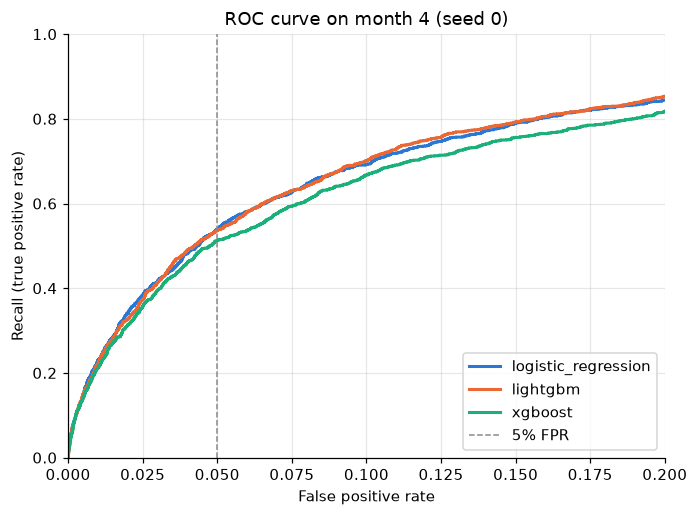

In [32]:
# ROC curves
plt.figure(figsize=(7, 5))
for model_name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_validation, first_seed_scores[model_name])
    plt.plot(fpr, tpr, color=MODEL_COLOURS[model_name], linewidth=2, label=model_name)
plt.axvline(TARGET_FPR, color=GREY, linestyle='--', linewidth=1, label='5% FPR')
plt.xlim(0, 0.2)
plt.ylim(0, 1)
plt.title('ROC curve on month 4 (seed 0)')
plt.xlabel('False positive rate')
plt.ylabel('Recall (true positive rate)')
plt.legend()
plt.show()

**Findings**
- Untuned, LightGBM (0.541) and logistic regression (0.539) are tied within noise, and their ROC curves overlap almost everywhere at low false positive rates. XGBoost is lower (0.503) and the least stable across seeds (±0.012).
- These scores mostly reflect each library's default settings, not what each model can do, so all three are tuned before choosing.

## **6. Tuning**
All three models are tuned with the same effort, and the best *tuned* model is picked programmatically.

We use **Optuna**: it tries a combination of settings, scores it on month 4, and uses the results so far to choose the next combination. Each trial uses seed 0 to keep it quick. Picking the single best trial would reward luck, so afterwards each model's top 3 trials **and its starting settings** are re-run over all 5 seeds, and the best average wins.

`scale_pos_weight` (tree models) and `class_weight` (logistic regression) control how much extra weight the fraud cases get during training. They are how the models deal with fraud being only 1% of applications.

In [33]:
N_TRIALS = 50   # per model


def suggest_params(trial, model_name):
    """The settings Optuna is allowed to try for each model."""
    if model_name == 'lightgbm':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 8, 128, log=True),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 500, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.001, 10, log=True),
            'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 50, log=True),
        }
    if model_name == 'xgboost':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'min_child_weight': trial.suggest_float('min_child_weight', 1, 50, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.001, 10, log=True),
            'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 50, log=True),
        }
    if model_name == 'logistic_regression':
        return {
            'C': trial.suggest_float('C', 0.001, 10, log=True),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    raise ValueError(f'unknown model: {model_name}')


def objective(trial, model_name):
    """One trial: fit with the suggested settings and return recall at 5% FPR on month 4."""
    params = suggest_params(trial, model_name)
    model = make_model(model_name, seed=0, params=params)
    model.fit(X_train, y_train)
    scores = model.predict_proba(X_validation)[:, 1]
    return recall_at_fpr(y_validation, scores)


optuna.logging.set_verbosity(optuna.logging.WARNING)

studies = {}
for model_name in MODEL_NAMES:
    start = time.time()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(lambda trial: objective(trial, model_name), n_trials=N_TRIALS)
    studies[model_name] = study
    minutes = (time.time() - start) / 60
    print(f'{model_name:20s} best trial: {study.best_value:.4f}  ({minutes:.1f} min)')

logistic_regression  best trial: 0.5448  (1.9 min)
lightgbm             best trial: 0.5792  (5.7 min)
xgboost              best trial: 0.5833  (7.1 min)


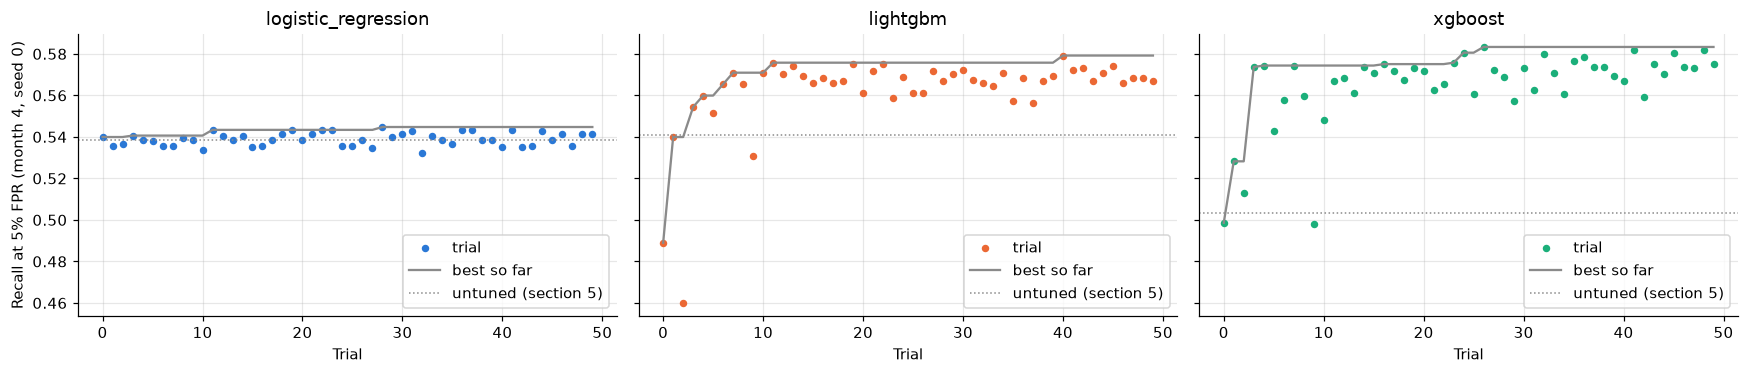

In [34]:
# Score of every trial, and the best score found so far, for each model
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5), sharey=True)
for ax, model_name in zip(axes, MODEL_NAMES):
    trials = studies[model_name].trials_dataframe()
    ax.scatter(trials['number'], trials['value'], color=MODEL_COLOURS[model_name], s=15, label='trial')
    ax.plot(trials['number'], trials['value'].cummax(), color=GREY, linewidth=1.5, label='best so far')
    ax.axhline(comparison.loc[model_name, 'recall@5%FPR (mean)'], color=GREY, linestyle=':',
               linewidth=1, label='untuned (section 5)')
    ax.set_title(model_name)
    ax.set_xlabel('Trial')
    ax.legend(loc='lower right')
axes[0].set_ylabel('Recall at 5% FPR (month 4, seed 0)')
plt.tight_layout()
plt.show()

In [35]:
# Re-run each model's top 3 trials and its starting settings over all 5 seeds
candidate_params = {}   # (model, candidate) -> settings
rows = []
for model_name in MODEL_NAMES:
    trials = studies[model_name].trials_dataframe().sort_values('value', ascending=False)
    candidates = {'starting settings': {}}
    for number in trials['number'].head(3):
        candidates[f'trial {number}'] = studies[model_name].trials[number].params

    for candidate, params in candidates.items():
        results, _ = validation_results(model_name, X_train, X_validation, params)
        candidate_params[(model_name, candidate)] = params
        rows.append({'model': model_name, 'candidate': candidate, **summarise(results)})

candidate_table = pd.DataFrame(rows).round(4)
candidate_table

,model,candidate,recall@5%FPR (mean),recall@5%FPR (std),ROC-AUC (mean),PR-AUC (mean)
0,logistic_regression,starting settings,0.5386,0.0000,0.9003,0.1514
1,logistic_regression,trial 28,0.5448,0.0000,0.9007,0.1523
2,logistic_regression,trial 22,0.5434,0.0000,0.9005,0.1516
3,logistic_regression,trial 36,0.5434,0.0000,0.9004,0.1515
4,lightgbm,starting settings,0.5409,0.0056,0.9032,0.1391
5,lightgbm,trial 40,0.5770,0.0045,0.9115,0.1833
6,lightgbm,trial 11,0.5736,0.0019,0.9101,0.1812
7,lightgbm,trial 22,0.5762,0.0032,0.9114,0.1837
8,xgboost,starting settings,0.5033,0.0120,0.8875,0.1309
9,xgboost,trial 26,0.5815,0.0013,0.9111,0.1869


In [36]:
# Best candidate for each model, then the best model overall
tuned_rows = []
for model_name in MODEL_NAMES:
    model_rows = candidate_table[candidate_table['model'] == model_name]
    tuned_rows.append(model_rows.loc[model_rows['recall@5%FPR (mean)'].idxmax()])

tuned = pd.DataFrame(tuned_rows).set_index('model')
tuned['untuned recall (section 5)'] = comparison['recall@5%FPR (mean)']
display(tuned)

best_model_name = tuned['recall@5%FPR (mean)'].idxmax()
best_params = candidate_params[(best_model_name, tuned.loc[best_model_name, 'candidate'])]
print('Final model:', best_model_name, '-', tuned.loc[best_model_name, 'candidate'])
print('Settings:', best_params)

,candidate,recall@5%FPR (mean),recall@5%FPR (std),ROC-AUC (mean),PR-AUC (mean),untuned recall (section 5)
model,,,,,,
logistic_regression,trial 28,0.5448,0.0000,0.9007,0.1523,0.5386
lightgbm,trial 40,0.5770,0.0045,0.9115,0.1833,0.5409
xgboost,trial 26,0.5815,0.0013,0.9111,0.1869,0.5033


Final model: xgboost - trial 26
Settings: {'n_estimators': 477, 'learning_rate': 0.07294723991702877, 'max_depth': 3, 'min_child_weight': 7.898594245470395, 'subsample': 0.8478777731058872, 'colsample_bytree': 0.6718663639765685, 'reg_lambda': 2.515289651928717, 'scale_pos_weight': 25.906544233330774}


**Findings**
- **Tuning matters a lot for the tree models:** XGBoost improves by +0.078 (0.503 to 0.582) and LightGBM by +0.036 (0.541 to 0.577). Logistic regression barely moves (+0.006 to 0.545). Choosing on the untuned results would have picked the wrong model.
- **Final model: XGBoost**, with recall at 5% FPR of 0.582 ± 0.001, ROC-AUC 0.911 and PR-AUC 0.187 on month 4.
- XGBoost and LightGBM are effectively **tied** (0.004 apart, below the month-4 noise); LightGBM would have been an equally reasonable choice.
- The chosen settings use shallow trees (`max_depth` 3, 477 trees) and give each fraud case about 26x the weight of a genuine one. Because of that weighting the scores are **not probabilities**: the 5%-FPR threshold sits around 0.47 although only about 1% of applications are fraud.

## **7. Freeze the Final Model**
The final model is trained once per seed on months 0-3 with the chosen settings. For each seed, the threshold is picked on **month 5** so that 5% of genuine applications are flagged. From here on nothing about the model changes.

Saved files:
- `configs/final_model.json`: the model, its settings, the feature options and the thresholds (small, committed to git)
- `outputs/models/`: the trained model for each seed (committed to git, so later notebooks can use them without re-running this one)

In [37]:
os.makedirs('../configs', exist_ok=True)
os.makedirs('../outputs/models', exist_ok=True)

X_calibration = make_features(calibration, **FINAL_FEATURES)

final_models = {}
thresholds = {}
for seed in SEEDS:
    model = make_model(best_model_name, seed, best_params)
    model.fit(X_train, y_train)
    final_models[seed] = model
    joblib.dump(model, f'../outputs/models/{best_model_name}_seed{seed}.joblib')

    # the threshold that flags 5% of genuine applications in month 5
    calibration_scores = model.predict_proba(X_calibration)[:, 1]
    thresholds[seed] = float(threshold_at_fpr(y_calibration, calibration_scores))

final_model = {
    'model': best_model_name,
    'params': best_params,
    'features': FINAL_FEATURES,
    'trained_on_months': TRAIN_MONTHS,
    'threshold_picked_on_months': CALIBRATION_MONTHS,
    'thresholds': {str(seed): threshold for seed, threshold in thresholds.items()},
}
with open('../configs/final_model.json', 'w') as f:
    json.dump(final_model, f, indent=2)

print(json.dumps(final_model, indent=2))

{
  "model": "xgboost",
  "params": {
    "n_estimators": 477,
    "learning_rate": 0.07294723991702877,
    "max_depth": 3,
    "min_child_weight": 7.898594245470395,
    "subsample": 0.8478777731058872,
    "colsample_bytree": 0.6718663639765685,
    "reg_lambda": 2.515289651928717,
    "scale_pos_weight": 25.906544233330774
  },
  "features": {
    "missing_flags": true,
    "drifting": "ratio",
    "valid_phones": false,
    "include_age": true
  },
  "trained_on_months": [
    0,
    1,
    2,
    3
  ],
  "threshold_picked_on_months": [
    5
  ],
  "thresholds": {
    "0": 0.4748513400554657,
    "1": 0.47353819012641907,
    "2": 0.47703808546066284,
    "3": 0.4765724837779999,
    "4": 0.473818302154541
  }
}


## **8. Score on Base and All 5 Variants**
The frozen model, with its month-5 thresholds, scores months 6-7 of Base and of every variant. Nothing is refit or re-tuned. **Once this section has been run, the earlier sections should not be changed**: otherwise the test results would start steering the model.

For each dataset we report:
- **Ranking quality**, recomputed on that dataset: recall at 5% FPR (main metric), ROC-AUC, PR-AUC.
- **The frozen threshold**: recall, FPR and precision when the month-5 threshold is applied unchanged. If the FPR here is far from 5%, the threshold doesn't carry over to that dataset.
- **Fairness**: FPR for each age group (50+ vs under 50) and **predictive equality**, the BAF paper's fairness metric: lower group FPR / higher group FPR, so 1 means genuine applicants in both groups are wrongly flagged equally often.

Note: Variant IV's test months contain exactly the same applications as Variant III's, so the two give identical results. The bias in IV and V is only in months 0-5, which the Base model never sees.

In [38]:
def evaluate(y_true, scores, threshold, ages):
    """The numbers reported for one dataset."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    flagged = scores >= threshold
    fraud = y_true == 1
    genuine = y_true == 0
    is_50_plus = np.asarray(ages) >= 50

    fpr_50_plus = flagged[genuine & is_50_plus].mean()
    fpr_under_50 = flagged[genuine & ~is_50_plus].mean()

    return {
        'recall@5%FPR': recall_at_fpr(y_true, scores),
        'ROC-AUC': roc_auc_score(y_true, scores),
        'PR-AUC': average_precision_score(y_true, scores),
        'recall at threshold': flagged[fraud].mean(),
        'FPR at threshold': flagged[genuine].mean(),
        'precision at threshold': y_true[flagged].mean(),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': min(fpr_50_plus, fpr_under_50) / max(fpr_50_plus, fpr_under_50),
    }

In [39]:
os.makedirs('../outputs/predictions', exist_ok=True)

rows = []
for dataset, file_name in DATASET_FILES.items():
    df = pd.read_csv(f'{DATA_DIR}/{file_name}')
    test = df[df['month'].isin(TEST_MONTHS)]
    X_test = make_features(test, **FINAL_FEATURES)

    for seed, model in final_models.items():
        scores = model.predict_proba(X_test)[:, 1]
        results = evaluate(test[TARGET], scores, thresholds[seed], test['customer_age'])
        rows.append({'dataset': dataset, 'seed': seed, **results})

        if seed == SEEDS[0]:
            # keep the seed-0 scores for later analysis (calibration, fairness, review queue)
            pd.DataFrame({
                'row_id': test.index,
                'month': test['month'].to_numpy(),
                'y_true': test[TARGET].to_numpy(),
                'score': scores,
                'customer_age': test['customer_age'].to_numpy(),
            }).to_csv(f'../outputs/predictions/{dataset}_test_seed0.csv', index=False)

    print(f'{dataset:12s} scored: {len(test):,} test rows')
    del df

test_results = pd.DataFrame(rows)

base         scored: 205,011 test rows
variant_i    scored: 205,010 test rows
variant_ii   scored: 205,010 test rows
variant_iii  scored: 241,672 test rows
variant_iv   scored: 241,672 test rows
variant_v    scored: 241,672 test rows


In [40]:
# Mean over the 5 seeds for each dataset (plus the spread of the main metric)
summary = test_results.drop(columns='seed').groupby('dataset', sort=False).mean()
summary.insert(1, 'recall@5%FPR (std)', test_results.groupby('dataset', sort=False)['recall@5%FPR'].std())
summary.round(4)

,recall@5%FPR,recall@5%FPR (std),ROC-AUC,PR-AUC,recall at threshold,FPR at threshold,precision at threshold,FPR 50+,FPR under 50,predictive equality
dataset,,,,,,,,,,
base,0.5482,0.0018,0.8937,0.1968,0.5615,0.0531,0.1308,0.1266,0.0389,0.3072
variant_i,0.5136,0.0033,0.8841,0.1775,0.5093,0.0491,0.1287,0.1281,0.0394,0.3076
variant_ii,0.5505,0.0009,0.8969,0.2090,0.6605,0.0836,0.1011,0.1280,0.0391,0.3054
variant_iii,0.4676,0.0019,0.8700,0.1258,0.5842,0.0842,0.0715,0.1282,0.0392,0.3058
variant_iv,0.4676,0.0019,0.8700,0.1258,0.5842,0.0842,0.0715,0.1282,0.0392,0.3058
variant_v,0.4835,0.0028,0.8729,0.1323,0.5934,0.0832,0.0734,0.1264,0.0390,0.3089


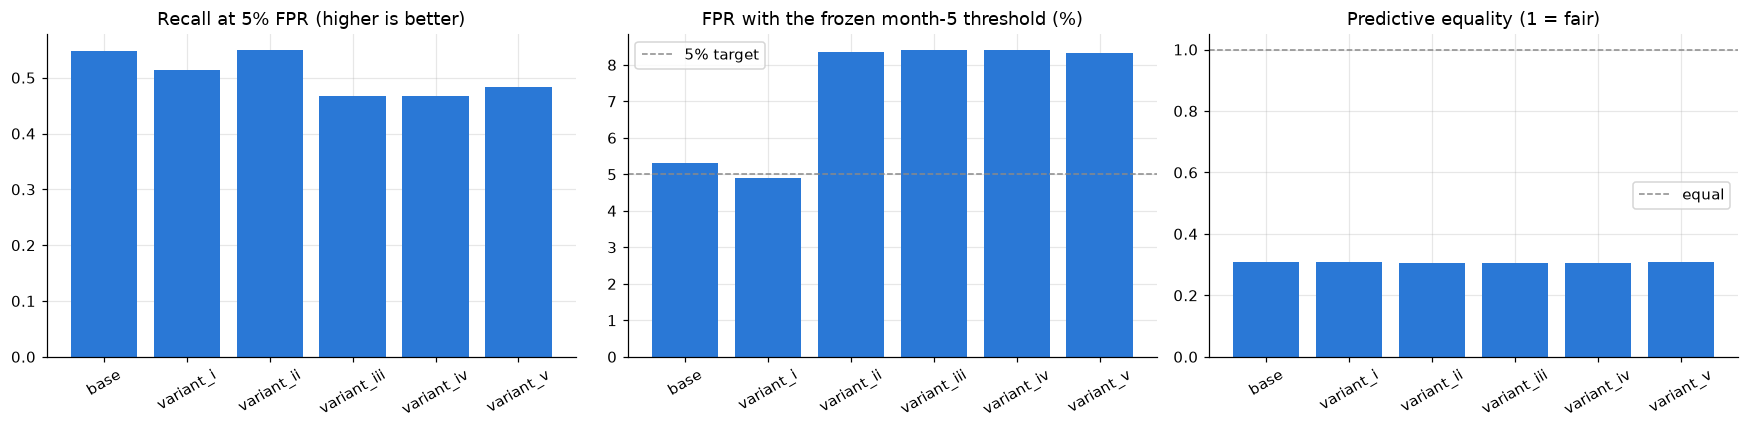

In [41]:
# Main metric, frozen-threshold FPR and fairness for each dataset
datasets = list(summary.index)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(datasets, summary['recall@5%FPR'], color=BLUE)
axes[0].set_title('Recall at 5% FPR (higher is better)')

axes[1].bar(datasets, summary['FPR at threshold'] * 100, color=BLUE)
axes[1].axhline(TARGET_FPR * 100, color=GREY, linestyle='--', linewidth=1, label='5% target')
axes[1].set_title('FPR with the frozen month-5 threshold (%)')
axes[1].legend()

axes[2].bar(datasets, summary['predictive equality'], color=BLUE)
axes[2].axhline(1, color=GREY, linestyle='--', linewidth=1, label='equal')
axes[2].set_title('Predictive equality (1 = fair)')
axes[2].set_ylim(0, 1.05)
axes[2].legend()

for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Findings**

On the Base test months (205,011 applications, mean over 5 seeds):
- **Ranking quality:** recall at 5% FPR 0.548 (seed standard deviation 0.002), ROC-AUC 0.894, PR-AUC 0.197. This is below the 0.582 of the tuning month 4 (section 6): month 4 picked the settings, so its score is optimistic, and the test months are further from training.
- **At the frozen threshold:** recall 0.562, FPR 5.3% (the target was 5%), precision 0.131. About 1 in 8 flagged applications is fraud.

On the variants, scored unchanged:
- **Ranking quality holds on Variants I and II** (recall at 5% FPR 0.514 and 0.551) and **drops on Variants III-V** (0.468-0.483).
- **The month-5 threshold does not carry over.** It keeps the FPR near target on Variant I (4.9%) but flags 8.3-8.4% of genuine applicants on Variants II-V.
- Variants III and IV give identical results (same test applications, see the note above).

Fairness:
- **Genuine applicants aged 50+ are wrongly flagged 3.3 times as often** as those under 50: FPR 12.7% against 3.9% on Base, predictive equality 0.31, and the same (0.305-0.309) on every variant.

**What the next notebooks take from here**
- **Notebook 03** uses the frozen model to decide which fraud alerts a human analyst should review (FiFAR).
- **Notebook 04** asks how certain these test numbers are, and what to do about a threshold that does not hold its 5% FPR (section 10 there).
- **Notebook 05** explains what the frozen model relies on.
- **Notebook 06** examines the age gap (predictive equality 0.31): where it comes from and what reduces it.

Notebooks 03-06 all load the saved model (`configs/final_model.json`, `outputs/models/`) and never change it.